# 03 · Distributions and Relationship with the Target

**Objective:** describe how each variable in the dataset is distributed and how it relates to the
target `is_canceled`, in order to identify which variables are useful for predicting booking
cancellations and which transformations they will need before modelling (encoding, binning, scaling).

**Scope:**
- Includes: variable inventory and data types, class balance of the target, distributions of
  numerical and categorical variables, cancellation rate by variable, and a preliminary selection of
  useful variables, including a check for variables not available at booking time (data leakage).
- Does not include: duplicates, missing and erroneous values (→ `01_cleaning`), or outlier
  detection and treatment (→ `02_outliers`).

**Data:** the clean dataset produced by `01_cleaning` (`data/hotels_clean.csv`, 86,622 bookings ×
32 columns, after removing duplicates and invalid rows). Run `01_cleaning` first to create it.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 3.0.6 | seaborn 0.13.2


In [2]:
csv_path = "../data/hotels_clean.csv"   # created by 01_cleaning.ipynb (run it first)
df = pd.read_csv(csv_path)
df.shape

(86622, 32)

## 1. Variable inventory

In [3]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,No agent,No company,0,Transient,75.0,0,0,Check-Out,2015-07-02
1,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304,No company,0,Transient,75.0,0,0,Check-Out,2015-07-02
2,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240,No company,0,Transient,98.0,0,1,Check-Out,2015-07-03
3,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,No agent,No company,0,Transient,107.0,0,0,Check-Out,2015-07-03
4,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,No Deposit,303,No company,0,Transient,103.0,0,1,Check-Out,2015-07-03


In [4]:
inventory = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "example": df.iloc[0],
})
inventory

,dtype,n_unique,n_missing,example
hotel,str,2,0,Resort Hotel
is_canceled,int64,2,0,0
lead_time,int64,478,0,7
arrival_date_year,int64,3,0,2015
arrival_date_month,str,12,0,July
arrival_date_week_number,int64,53,0,27
arrival_date_day_of_month,int64,31,0,1
stays_in_weekend_nights,int64,17,0,0
stays_in_week_nights,int64,33,0,1
adults,int64,7,0,1


In [5]:
target = "is_canceled"
numerical_continuous = ["adr", "lead_time", "days_in_waiting_list"]
numerical_counts = ["adults", "children", "babies", "previous_cancellations","previous_bookings_not_canceled", "booking_changes", "required_car_parking_spaces", "total_of_special_requests", "stays_in_weekend_nights", "stays_in_week_nights"]
binary = ["is_repeated_guest"]
categorical = ["meal", "hotel", "deposit_type", "reserved_room_type", "assigned_room_type", "customer_type", "market_segment", "distribution_channel", "country"]
id_codes = ["agent", "company"]
date_parts = ["arrival_date_year", "arrival_date_month", "arrival_date_week_number", "arrival_date_day_of_month"]
leakage = ["reservation_status", "reservation_status_date"]

In [6]:
all_columns = [target] + numerical_continuous + numerical_counts + binary + categorical + id_codes + date_parts + leakage

print(len(all_columns), "assigned |", len(df.columns), "in the dataset")
print("Every column assigned exactly once: ", sorted(all_columns) == sorted(df.columns))

32 assigned | 32 in the dataset
Every column assigned exactly once:  True


### Conclusions and actions: variable inventory

**Conclusions**

- After cleaning, the dataset has 86,622 bookings and 32 columns. It started with 119,390;
  `01_cleaning` removed the duplicates and the invalid rows. There are no missing values left.

- Sorting the columns by what they mean gives: 1 target, 3 continuous, 10 counts, 1 binary,
  9 categorical, 2 ID codes, 4 parts of the arrival date and 2 leakage columns.

- The type pandas gives a column doesn't always match what it means:
  - `is_canceled` and `is_repeated_guest` look like numbers, but they are just yes/no (0/1).
  - `agent` and `company` are codes, not quantities: agent 240 isn't "more" than agent 9. In the raw
    file they were `float` because of the `NULL` values; `01_cleaning` replaced those with
    "No agent" / "No company", so they are now text.
  - `arrival_date_month` and `reservation_status_date` are stored as text, not as dates.

- `reservation_status` gives away the answer: every Canceled (22,973) and No-Show (999) booking has
  `is_canceled = 1`, and every Check-Out (62,650) has `is_canceled = 0`. `reservation_status_date`
  is the date of that final status. Both are only known once the booking is over, so they can't be
  used to predict it.

**Actions**

- Use a different analysis for each group: histograms and boxplots for continuous variables, bar
  charts for counts, and frequency tables with the cancellation rate per category for the rest.

- Put the months in calendar order before plotting (alphabetically, April would come first).

- Treat `agent` and `company` as categories and never average them. They have hundreds of codes,
  so the rare ones will have to be grouped before modelling.

- Leave `reservation_status` and `reservation_status_date` out of the features and explain why in
  the README. Three more columns (`booking_changes`, `assigned_room_type`, `days_in_waiting_list`)
  might also only be known after booking; we keep them for now and check them in the leakage section.

## 2. Target: class balance

In [7]:
counts = df[target].value_counts()
proportions = df[target].value_counts(normalize=True)
pd.DataFrame({"count": counts, "proportion": proportions.round(3)})

,count,proportion
is_canceled,,
0,62650,0.723
1,23972,0.277


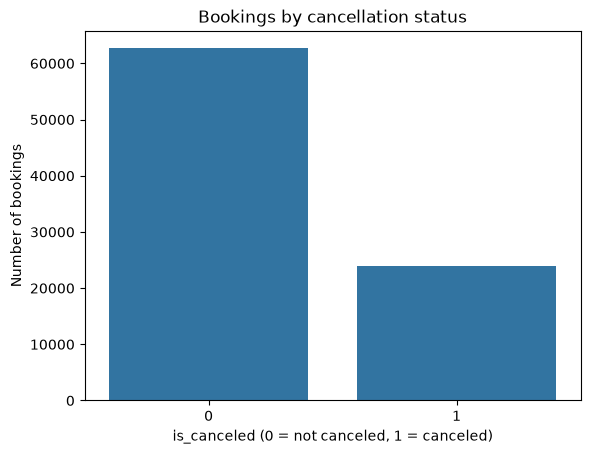

In [8]:
sns.countplot(data=df, x=target)
plt.title("Bookings by cancellation status")
plt.xlabel("is_canceled (0 = not canceled, 1 = canceled)")
plt.ylabel("Number of bookings")
plt.show()

### Conclusions and actions: target

**Conclusions**

- After cleaning, 23,972 of the 86,622 bookings were cancelled (27.7%) and 62,650 were not (72.3%).
  In other words, a bit more than one booking in four ends up cancelled. The bar chart shows it:
  the "not canceled" bar is about two and a half times taller than the "canceled" one.

- In the raw file the rate was 37%. The drop comes from the duplicates removed in `01_cleaning`:
  63% of them were cancellations, so removing them took out far more cancelled bookings than
  non-cancelled ones. The cleaning didn't just make the dataset smaller, it changed the target.

- The two classes are not balanced, but this isn't an extreme case like fraud detection, where
  positives can be 1% or less. There are enough cancellations for a model to learn from.

- The imbalance does matter when judging a model. A "model" that always answers "not canceled"
  would be right 72.3% of the time without detecting a single cancellation. So any real model has
  to beat 72.3% accuracy, and accuracy alone won't tell us whether it actually finds cancellations.

- The cancelled class also includes 999 No-Shows (4.2% of all cancellations). We keep them
  together: for the hotel, a guest who cancels and a guest who doesn't turn up both leave an empty
  room. The only difference is that a cancellation gives the hotel some time to resell the room.

**Actions**

- Use 27.7% as the reference rate in the next sections: a group of bookings is higher risk only if
  its cancellation rate is clearly above it.

- When building the model, split train and test in a stratified way, so both keep the 72/28
  proportion, and report recall (sensitivity), precision and AUC next to accuracy, always compared
  with the 72.3% baseline.

- In the README, define the positive class as "cancelled or no-show" and add the class balance
  (27.7% cancelled) to the problem formulation, where it is still marked "to be completed".

## 3. Distributions

### 3a. Continuous variables

The per-hotel distributions and outliers of `adr` and `lead_time` are in `02_outliers`.
Here they are split by cancellation status instead.

In [9]:
df[numerical_continuous].describe().T   # transposed (swaps rows and columns)

,count,mean,std,min,25%,50%,75%,max
adr,86622.0,107.262146,54.354063,0.0,72.9,99.0,134.46,5400.0
lead_time,86622.0,80.254497,86.022116,0.0,12.0,50.0,125.00,709.0
days_in_waiting_list,86622.0,0.750398,10.030402,0.0,0.0,0.0,0.00,391.0


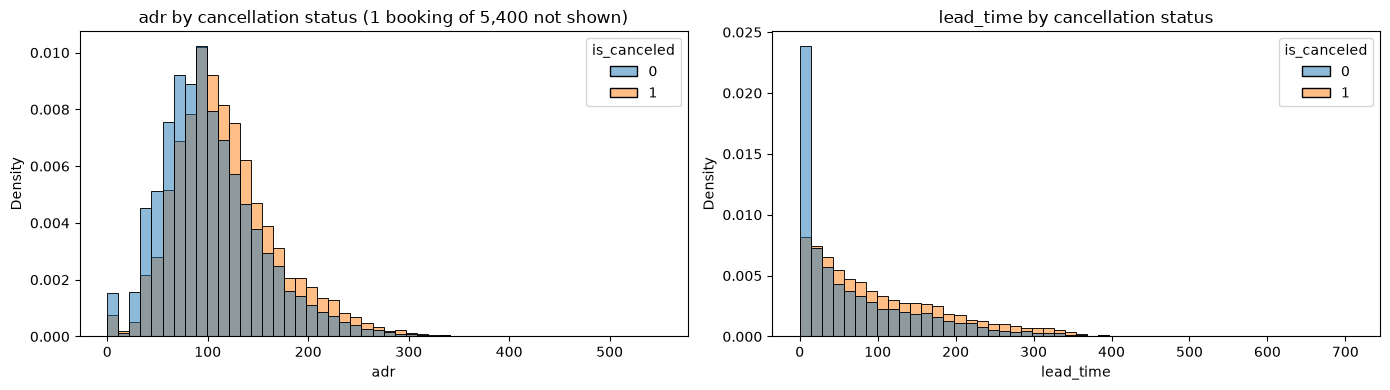

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(data=df, x="adr", hue=target, stat="density", common_norm=False,
             bins=50, binrange=(0, 550), ax=axes[0])
axes[0].set_title("adr by cancellation status (1 booking of 5,400 not shown)")

sns.histplot(data=df, x="lead_time", hue=target, stat="density", common_norm=False,
             bins=50, ax=axes[1])
axes[1].set_title("lead_time by cancellation status")

plt.tight_layout()
plt.show()

There are 2.6 times more non-cancelled bookings, so with raw counts the “canceled” bars would always look smaller. ``stat="density"`` and ``common_norm=False`` scale each class to the same total, so we compare the shapes: where each class’s bookings concentrate. ``binrange=(0, 550)`` keeps the single 5,400 booking from squashing the plot.

In [11]:
df.groupby(target)[["adr", "lead_time"]].median()

,adr,lead_time
is_canceled,,
0,95.0,38.0
1,109.8,80.0


In [12]:
print("Share with 0 days:", (df["days_in_waiting_list"] == 0).mean().round(3))
df.loc[df["days_in_waiting_list"] > 0, "days_in_waiting_list"].describe()

Share with 0 days: 0.99


count    854.000000
mean      76.113583
std       66.886599
min        1.000000
25%       33.000000
50%       59.000000
75%       99.000000
max      391.000000
Name: days_in_waiting_list, dtype: float64

### Conclusions and actions: continuous variables

**Conclusions**

- All three variables have a long tail to the right: the mean is above the median in every case.
  The tail is mild for `adr` (mean 107, median 99), clear for `lead_time` (80 vs 50) and extreme
  for `days_in_waiting_list` (0.75 vs 0).

- `lead_time` is where cancelled and non-cancelled bookings differ the most. Bookings that go ahead
  pile up in the first two weeks (the tall blue bar on the left), while cancelled ones are spread
  over longer lead times. The median is 38 days for bookings that go ahead and 80 days for cancelled
  ones: the further ahead a booking is made, the more time there is for plans to change.

- `adr`: the two distributions overlap a lot, so price on its own won't separate the classes well.
  Still, very cheap bookings (below about 50 per night) are mostly not cancelled, and cancelled
  bookings are a bit more frequent from about 100 per night upwards (median about 110 vs 95).

- `days_in_waiting_list`: 99% of bookings never waited. Only 854 did, with a median wait of 59 days.
  As a number of days, the variable is almost always 0.

**Actions**

- `lead_time`: probably one of the most useful features. Check the cancellation rate by range in
  section 4. Because of the long tail, use bins or a log transform for models that are sensitive to
  skewed variables (e.g. logistic regression); tree-based models don't need it.

- `adr`: keep it, but don't expect much from it on its own; compare the cancellation rate by price
  range in section 4. The 5,400 booking stays out of the plots until the team decides where it is
  removed.

- `days_in_waiting_list`: replace the number of days with a yes/no variable ("was on the waiting
  list"). It is also a leakage candidate, since the wait happens after the booking is made, so it is
  reviewed in section 5.

### 3b. Count variables

Total length of stay (`total_nights`) is analysed in `02_outliers`; here each count is looked at on its own.

In [13]:
counts_summary = pd.DataFrame({
    "share_zero": (df[numerical_counts] == 0).mean().round(3),
    "median": df[numerical_counts].median(),
    "max": df[numerical_counts].max(),
    "n_unique": df[numerical_counts].nunique(),
})
counts_summary.sort_values("share_zero", ascending=False)

,share_zero,median,max,n_unique
babies,0.990,0.0,2,3
previous_cancellations,0.981,0.0,26,15
previous_bookings_not_canceled,0.960,0.0,72,73
required_car_parking_spaces,0.916,0.0,8,5
children,0.904,0.0,3,4
booking_changes,0.819,0.0,18,19
total_of_special_requests,0.501,0.0,5,6
stays_in_weekend_nights,0.398,1.0,19,17
stays_in_week_nights,0.064,2.0,50,33
adults,0.003,2.0,6,7


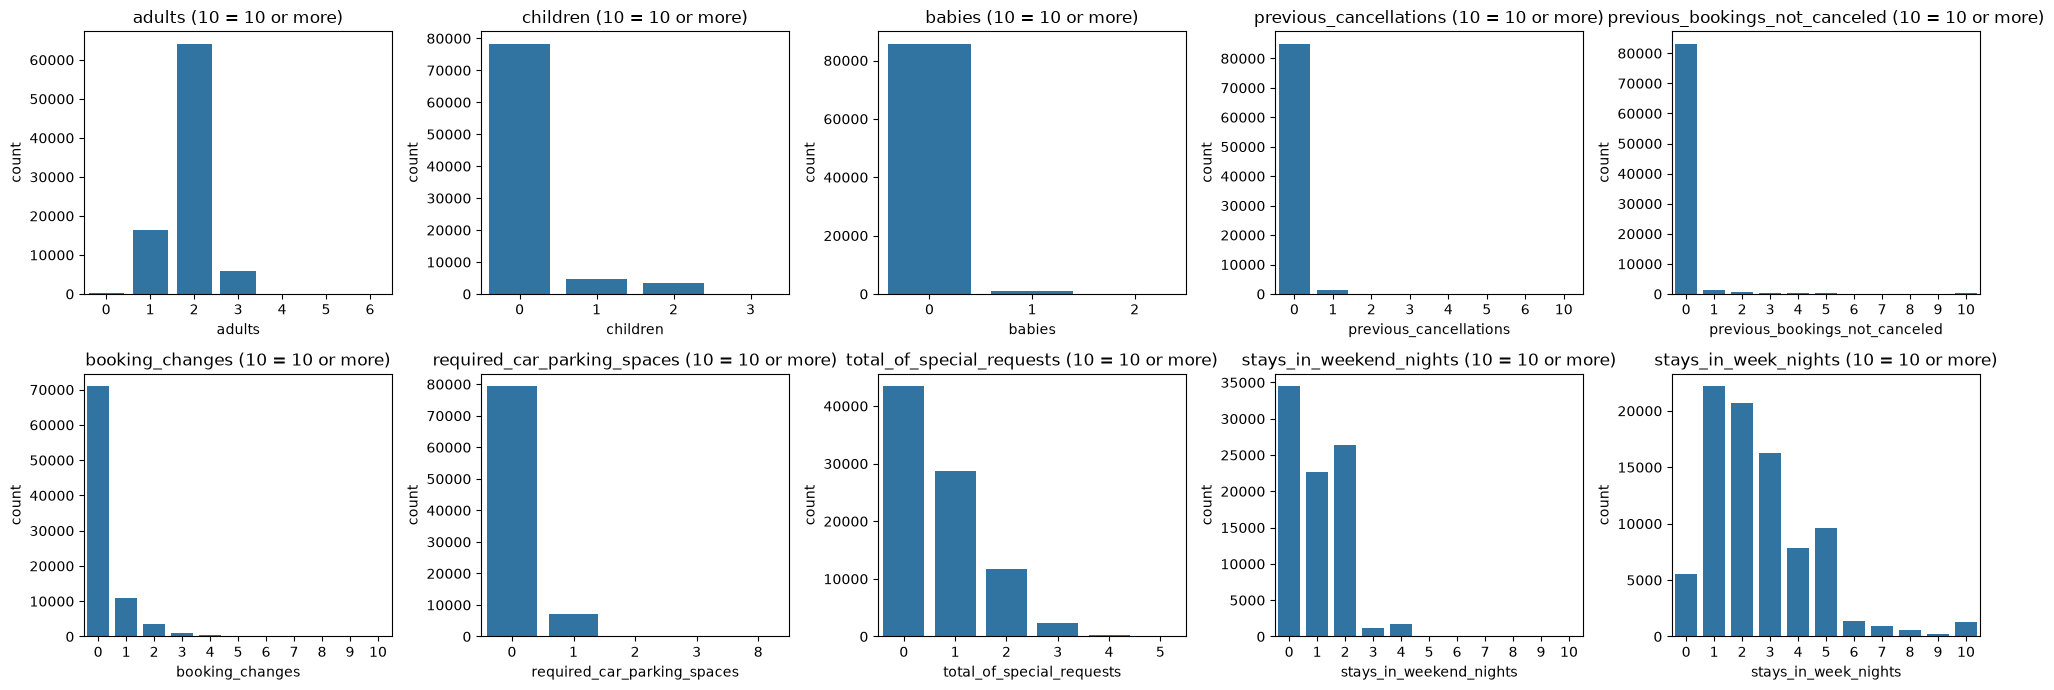

In [14]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, var in zip(axes.flat, numerical_counts):
    sns.countplot(x=df[var].clip(upper=10), ax=ax)
    ax.set_title(f"{var} (10 = 10 or more)")
plt.tight_layout()
plt.show()

Some counts go up to 50 or more (`stays_in_week_nights`, `previous_bookings_not_canceled`), which would give unreadable plots with dozens of tiny bars. That's why we use `.clip(upper=10)`: every value of 10 or more is grouped into the last bar, labelled 10.

### Conclusions and actions: count variables

**Conclusions**

- Most counts are almost always 0. Five are 0 for at least 90% of bookings: `babies` (99.0%),
  `previous_cancellations` (98.1%), `previous_bookings_not_canceled` (96.0%),
  `required_car_parking_spaces` (91.6%) and `children` (90.4%). `booking_changes` is close (81.9%).
  For these, what matters is mostly whether the value is 0 or not, not the exact number.

- The maximums are far from the typical values (26 previous cancellations, 72 previous bookings,
  8 parking spaces), but they are very rare. `02_outliers` leaves these counts out of the IQR
  analysis because their IQR is 0.

- The other counts have a real spread. `adults` is almost always 1 to 3, with 2 by far the most common
  (couples); only 0.3% have 0 adults, the bookings with children only that `01_cleaning` kept.
  Week nights are usually 1 to 4, with a small peak at 5 (a full working week), and weekend nights
  are 0, 1 or 2. Half of the bookings make no special request, and most of the rest make one or two.

**Actions**

- Turn the mostly-zero counts into yes/no variables: has children or babies, has cancelled before,
  has previous bookings, has changed the booking, has asked for parking. Section 4 checks whether
  these groups cancel at different rates.

- Keep `adults`, the nights and `total_of_special_requests` as counts, grouping the rare high values
  (e.g. "4 or more") if a model needs it.

- `booking_changes` and `required_car_parking_spaces` are leakage candidates: changes are counted
  until check-in or cancellation, and a parking space may only be recorded when the guest arrives
  with a car. Both are reviewed in section 5.

### 3c. Categorical, binary and date variables

In [15]:
cat_cols = categorical + id_codes + binary
cat_summary = pd.DataFrame({
    "n_categories": df[cat_cols].nunique(),
    "most_frequent": df[cat_cols].mode().iloc[0],
    "top_share": df[cat_cols].apply(lambda s: s.value_counts(normalize=True).iloc[0]).round(3),
    "n_rare (<1%)": df[cat_cols].apply(lambda s: (s.value_counts(normalize=True) < 0.01).sum()),
})
cat_summary.sort_values("n_categories", ascending=False)

,n_categories,most_frequent,top_share,n_rare (<1%)
company,348,No company,0.940,347
agent,334,9,0.331,322
country,178,PRT,0.310,164
assigned_room_type,11,A,0.532,4
reserved_room_type,9,A,0.646,2
market_segment,8,Online TA,0.592,3
meal,5,BB,0.778,2
distribution_channel,5,TA/TO,0.792,2
customer_type,4,Transient,0.824,1
deposit_type,3,No Deposit,0.987,1


- ``top_share`` is how much of the data the most common category takes. Close to 1 means the variable barely varies.

- ``n_rare`` is how many categories hold less than 1% of bookings each. Those are candidates for grouping into “Other”.

- ``lambda s``: ``apply`` runs once per column, where ``s`` is that column.

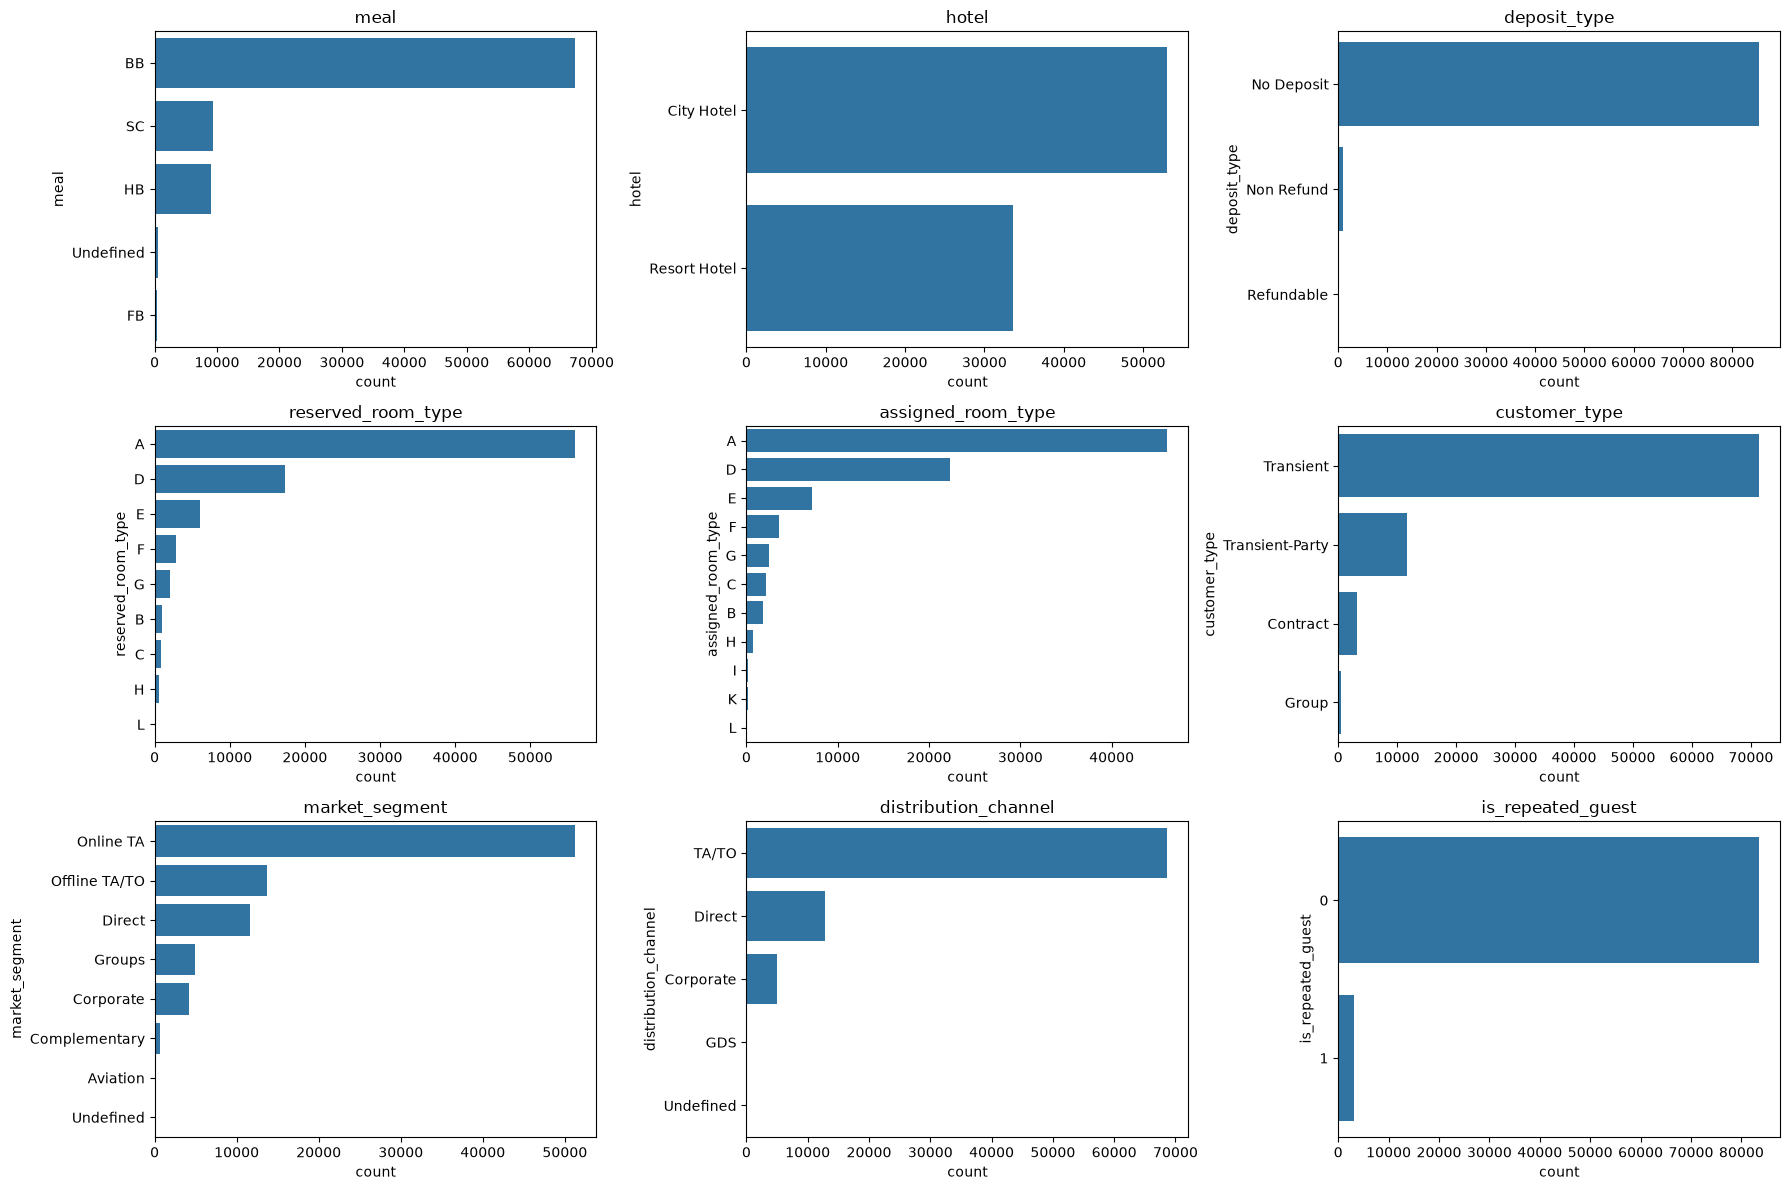

In [16]:
low_card = [c for c in categorical + binary if df[c].nunique() <= 15]
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for ax, var in zip(axes.flat, low_card):
    order = df[var].value_counts().index
    sns.countplot(data=df, y=var, order=order, ax=ax)
    ax.set_title(var)
plt.tight_layout()
plt.show()

Only the variables with up to 15 categories are plotted here (`country`, with 178, is left out).
The bars are horizontal so long labels stay readable, and sorted from most to least frequent.

In [17]:
for var in ["country", "agent", "company"]:
    top10_share = df[var].value_counts(normalize=True).head(10).sum()
    print(f"{var}: {df[var].nunique()} categories, top 10 cover {top10_share:.1%}")
    print(df[var].value_counts().head(5), "\n")

country: 178 categories, top 10 cover 81.6%
country
PRT    26849
GBR    10399
FRA     8813
ESP     7228
DEU     5385
Name: count, dtype: int64 

agent: 334 categories, top 10 cover 79.2%
agent
9           28653
240         12907
No agent    11950
14           3329
7            3282
Name: count, dtype: int64 

company: 348 categories, top 10 cover 96.8%
company
No company    81452
40              844
223             492
45              230
153             201
Name: count, dtype: int64 



`country`, `agent` and `company` have hundreds of categories, so instead of plotting them we check
how much of the data their 10 most frequent values cover.

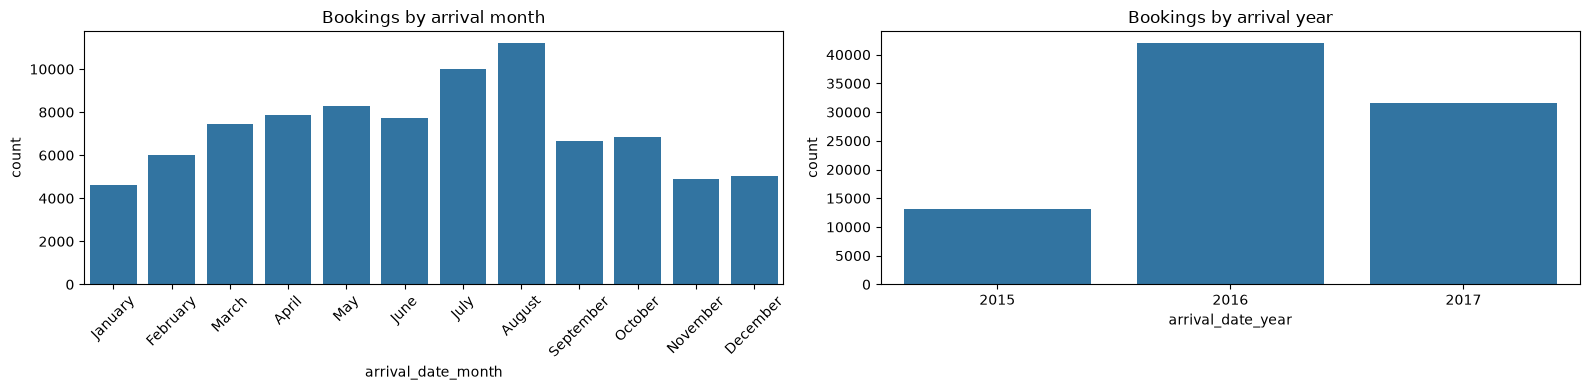

In [18]:
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.countplot(data=df, x="arrival_date_month", order=month_order, ax=axes[0])
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_title("Bookings by arrival month")
sns.countplot(data=df, x="arrival_date_year", ax=axes[1])
axes[1].set_title("Bookings by arrival year")
plt.tight_layout()
plt.show()

Months are plotted in calendar order, as planned in the inventory. The data covers arrivals from
July 2015 to August 2017, so 2015 and 2017 are incomplete years, and July and August appear in three
years while the other months appear in only two.

### Conclusions and actions: categorical, binary and date variables

**Conclusions**

- Several variables are dominated by one category: `deposit_type` (98.7% "No Deposit"),
  `is_repeated_guest` (96.4% not repeated), `company` (94.0% "No company"), `customer_type`
  (82.4% Transient), `distribution_channel` (79.2% TA/TO) and `meal` (77.8% BB). A small group can
  still matter if it cancels very differently, which section 4 checks (for example the 1,038
  "Non Refund" deposits).

- Some categories are tiny or unclear: `market_segment` has "Complementary" (682), "Aviation" (222)
  and "Undefined" (2), and `distribution_channel` has "GDS" (178) and "Undefined" (5). In `meal`,
  "Undefined" (485) means the same as "SC" (no meal package), according to the dataset documentation.

- `country`, `agent` and `company` have hundreds of categories, but a few cover most bookings: the
  top 10 countries cover 81.6% (Portugal alone 31.0%), the top 10 agents 79.2%, and for `company`
  almost every booking is "No company".

- `assigned_room_type` has two room types that never appear as reserved (I and K), and fewer bookings
  end up in room A than reserved it. The assigned room is decided by the hotel, often at check-in,
  which makes it a leakage candidate.

- By raw counts, August and July are the busiest months, but they appear in three years of data and
  the other months in only two, so the counts overstate them. 2015 (6 months) and 2017 (8 months)
  are incomplete years.

**Actions**

- Merge "Undefined" into "SC" in `meal`, and group the rare categories of `market_segment` and
  `distribution_channel` into "Other". "Complementary" is decided after section 4, since free stays
  may cancel differently.

- Keep the top 10 countries and agents and group the rest as "Other"; reduce `company` to a yes/no
  variable ("booked through a company").

- Compare months by cancellation rate (section 4), not by number of bookings. Don't use
  `arrival_date_year` as a feature: a model is applied to future years it has never seen, and the
  month already captures the season. `arrival_date_week_number` repeats the month's information.

- `assigned_room_type` joins the leakage candidates for section 5; `reserved_room_type` is known at
  booking and can be used instead.